In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [2]:
#read dataset
with open('sherlock-holm.es_stories_plain-text_advs.txt', 'r', encoding='utf-8') as file:
    text = file.read()

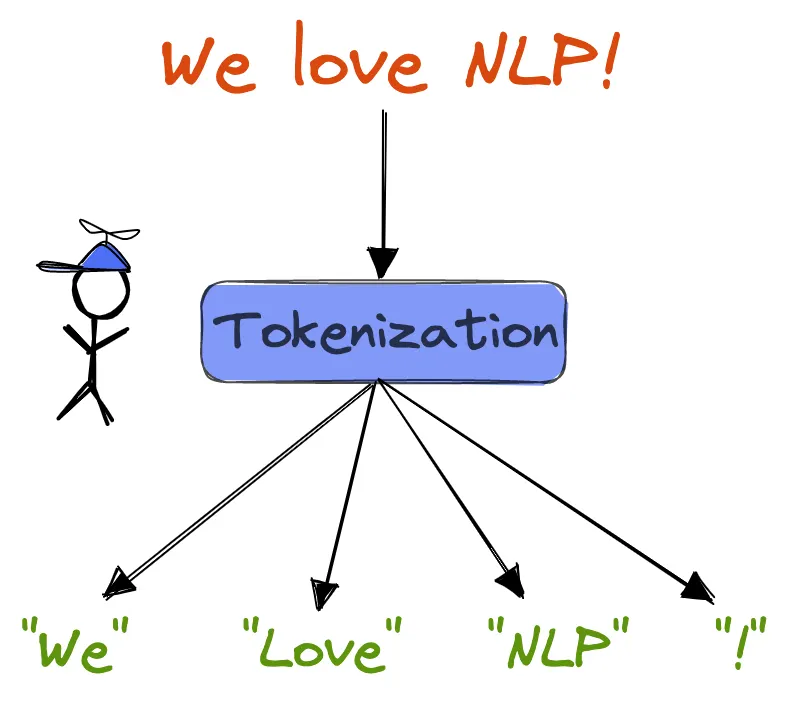

In [3]:
#Tokenizer process
tokenizer = Tokenizer()
#fit
tokenizer.fit_on_texts([text])
#assign length of word index
total_words = len(tokenizer.word_index) + 1

In [4]:
tokenizer.word_index

{'the': 1,
 'and': 2,
 'of': 3,
 'i': 4,
 'to': 5,
 'a': 6,
 'in': 7,
 'it': 8,
 'that': 9,
 'he': 10,
 'you': 11,
 'was': 12,
 'his': 13,
 'is': 14,
 'have': 15,
 'as': 16,
 'my': 17,
 'with': 18,
 'had': 19,
 'which': 20,
 'for': 21,
 'at': 22,
 'but': 23,
 'not': 24,
 'be': 25,
 'me': 26,
 'from': 27,
 'we': 28,
 'upon': 29,
 'holmes': 30,
 'said': 31,
 'this': 32,
 'him': 33,
 'there': 34,
 'so': 35,
 'on': 36,
 'been': 37,
 'very': 38,
 'what': 39,
 'no': 40,
 'your': 41,
 'then': 42,
 'one': 43,
 'all': 44,
 'by': 45,
 'are': 46,
 'man': 47,
 'she': 48,
 'were': 49,
 'an': 50,
 'her': 51,
 'would': 52,
 'mr': 53,
 'out': 54,
 'when': 55,
 'up': 56,
 'do': 57,
 'who': 58,
 'could': 59,
 "'": 60,
 'has': 61,
 'will': 62,
 'some': 63,
 'if': 64,
 'into': 65,
 'little': 66,
 'see': 67,
 'now': 68,
 'down': 69,
 'well': 70,
 'or': 71,
 'they': 72,
 'know': 73,
 'us': 74,
 'am': 75,
 'may': 76,
 'come': 77,
 'about': 78,
 'our': 79,
 'can': 80,
 'more': 81,
 'other': 82,
 'should': 83,

In [5]:
total_words

6305

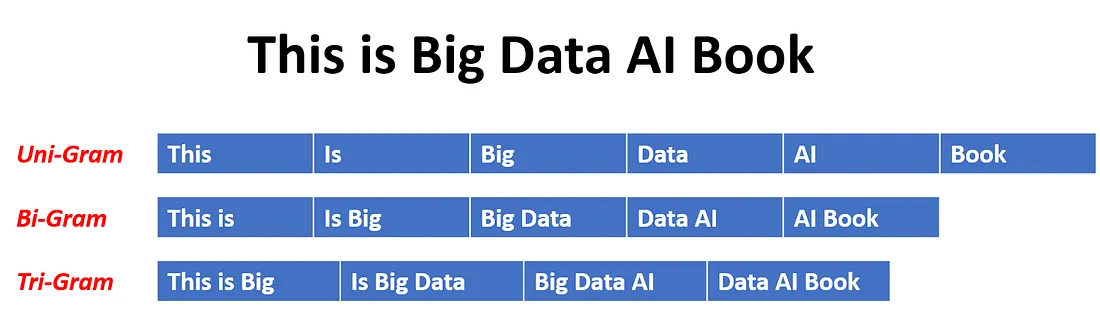

In [6]:
#declare ngrams
input_sequences = []
#split the sentence from '\n'
for line in text.split('\n'):
    #get tokens
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

In [7]:
input_sequences

[[1, 1118],
 [1, 1118, 3],
 [1, 1118, 3, 109],
 [1, 1118, 3, 109, 30],
 [3204, 3205],
 [3204, 3205, 3206],
 [263, 3],
 [263, 3, 1678],
 [6, 840],
 [6, 840, 7],
 [6, 840, 7, 572],
 [1, 157],
 [1, 157, 310],
 [1, 157, 310, 382],
 [6, 96],
 [6, 96, 3],
 [6, 96, 3, 1355],
 [1, 415],
 [1, 415, 841],
 [1, 415, 841, 383],
 [1, 253],
 [1, 253, 573],
 [1, 253, 573, 523],
 [1, 47],
 [1, 47, 18],
 [1, 47, 18, 1],
 [1, 47, 18, 1, 1119],
 [1, 47, 18, 1, 1119, 685],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 384],
 [1, 487, 3, 1, 384, 969],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 3207],
 [1, 487, 3, 1, 3207, 2219],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 3208],
 [1, 487, 3, 1, 3208, 1120],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 1356],
 [1, 487, 3, 1, 1356, 1357],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 2220],
 [1, 487, 3, 1, 2220, 3209],
 [1, 487],
 [1, 487, 3],
 [1, 487, 3, 1],
 [1, 487, 3, 1, 1358],
 [1, 487, 3

In [8]:
setence_token = input_sequences[40] # [1, 1561, 5, 129, 34]
sentence = []
for token in setence_token:
    sentence.append(list((tokenizer.word_index).keys())[list((tokenizer.word_index).values()).index(token)])
print(sentence)

['the', 'adventure', 'of', 'the']


In [9]:
#maximum sentence length
max_sequence_len = max([len(seq) for seq in input_sequences])
# input sequences
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

In [10]:
input_sequences

array([[   0,    0,    0, ...,    0,    1, 1118],
       [   0,    0,    0, ...,    1, 1118,    3],
       [   0,    0,    0, ..., 1118,    3,  109],
       ...,
       [   0,    0,    0, ...,    1, 6303, 6304],
       [   0,    0,    0, ..., 6303, 6304, 2223],
       [   0,    0,    0, ..., 6304, 2223, 2221]], dtype=int32)

In [11]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

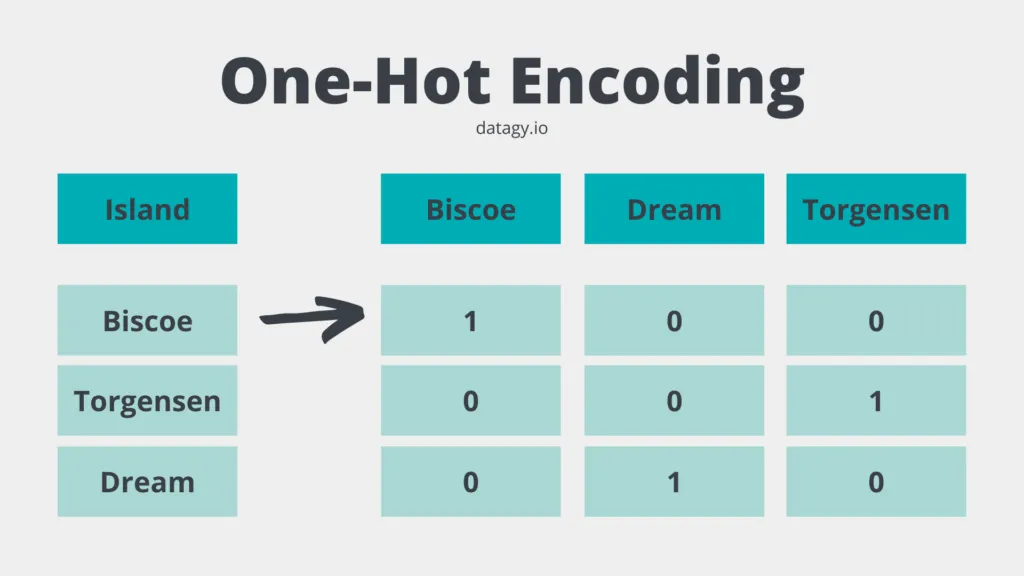

In [12]:
#convert one-hot-encode
y = np.array(tf.keras.utils.to_categorical(y, num_classes=total_words))

In [13]:
#create model

model = Sequential()
model.add(Embedding(total_words, 100, input_length=max_sequence_len-1))
model.add(LSTM(150))
model.add(Dense(total_words, activation='softmax'))

model.build(input_shape=(None, max_sequence_len - 1))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 16, 100)        │       630,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 150)            │       150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6305)           │       952,055 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,733,155 (6.61 MB)

 Trainable params: 1,733,155 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
#fit the model
model.fit(X, y, epochs=100, verbose=1)

Epoch 1/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.0673 - loss: 6.3823
Epoch 2/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.1021 - loss: 5.7219
Epoch 3/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.1279 - loss: 5.3453
Epoch 4/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.1446 - loss: 5.0343
Epoch 5/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.1648 - loss: 4.7303
Epoch 6/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.1824 - loss: 4.4338
Epoch 7/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.2022 - loss: 4.1490
Epoch 8/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.2310 - loss: 3.8730
Epoch 9/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.2639 - loss: 3.6093
Epoch 10/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.3002 - loss: 3.3566
Epoch 11/100
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.3402 - loss: 3.1200
Epoch 12

In [34]:
#determine a text
seed_text = "The fat man"
# predict word number
next_words = 11

for _ in range(next_words):
    #convert to token
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    #path sequences
    token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
    #model prediction
    predicted = np.argmax(model.predict(token_list), axis=-1)
    output_word = ""
    # get predict words
    for word, index in tokenizer.word_index.items():
        if index == predicted:
            output_word = word
            break
    seed_text += " " + output_word
    print(seed_text)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
The fat man cast
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
The fat man cast his
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
The fat man cast his eyes
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
The fat man cast his eyes round
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
The fat man cast his eyes round and
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
The fat man cast his eyes round and then
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
The fat man cast his eyes round and then up
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
The fat man cast his eyes round and then up at
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
The fat man cast his eyes round and then up at the
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
The fat man cast his eyes round and then up at the open
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
The fat man cast his eyes round and then up at the open skylight


In [40]:

#determine a text
seed_text = "And brought Miss"
# predict word number
next_words = 20

for _ in range(next_words):
    #convert to token
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    #path sequences
    token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
    #model prediction
    predicted = np.argmax(model.predict(token_list), axis=-1)
    output_word = ""
    # get predict words
    for word, index in tokenizer.word_index.items():
        if index == predicted:
            output_word = word
            break
    seed_text += " " + output_word
    print(seed_text)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
And brought Miss hunter
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
And brought Miss hunter down
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
And brought Miss hunter down from
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
And brought Miss hunter down from london
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
And brought Miss hunter down from london in
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
And brought Miss hunter down from london in order
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
And brought Miss hunter down from london in order to
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
And brought Miss hunter down from london in order to get
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
And brought Miss hunter down from london in order to get rid
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
And brought Miss hunter down from london in order to get rid of
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
And brought Miss hunter down from london in order to get rid of the
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
And brought Miss hu

In [42]:
#Save the trained model
model.save("next_word_model.keras")

In [43]:
import pickle

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)